# **Trabalho Prático 1** (TP1)
`49774`: Francisco Valentim | `51811`: Bruno Pereira

**Instituto Superior de Engenharia de Lisboa** (ISEL)<br>
**Licenciatura em Engenharia Informática e Multimédia** (LEIM)<br>
**Processamento de Sinais Multimédia** (PSM)

---

O processador tem três blocos. $(1)$ O primeiro é um equalizador de 3 bandas com filtros FIR (*Parte A*). $(2)$ O segundo é um reverberador de Schroeder com filtros IIR (*Parte B*). $(3)$ O terceiro mistura o som direto com o som reverberado.

O equalizador e o reverberador estão associados em série. A saída do equalizador, $x_{eq}[n]$, é a entrada do reverberador, que produz $y_{reverb}[n]$. O sinal resultante é $y[n] = (1 - \alpha)\, x_{eq}[n] + \alpha\, y_{reverb}[n].$

## $0.$ Bibliotecas, parâmetros e funções auxiliares

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import firwin, lfilter, freqz, unit_impulse
from scipy.io import wavfile
from IPython.display import Audio, display

In [2]:
Fs = 44100                               # frequência de amostragem (Hz)

AUDIO_IN  = 'audio/in'                   # sinais originais
AUDIO_OUT = 'audio/out'                  # sinais processados

In [3]:
def normalize(x):
    """Normaliza um sinal pelo pico.
    Args:
        x: Sinal.
    Returns:
        Sinal com max|x| = 0,99.
    """
    return 0.99 * x / np.max(np.abs(x))

def db(a):
    """Converte amplitude em dB.
    Args:
        a: Amplitude (real ou complexa).
    Returns:
        20·log10(|a| + 1e-12).
    """
    return 20 * np.log10(np.abs(a) + 1e-12) # 1e-12 para evitar log10(0)

def freq_response(b, a=1.0, worN=16384):
    """Resposta em frequência de um SLIT a partir dos coeficientes de H(z) = Y(z)/X(z).
    Args:
        b: Coeficientes do numerador.
        a: Coeficientes do denominador.
        worN: Nº de pontos em [0, Fs/2], ou vetor de frequências (Hz).
    Returns:
        (f, H): frequências (Hz) e H(e^jω).
    """
    return freqz(b, a, worN=worN, fs=Fs)

def read_wav(path):
    """Lê um ficheiro .wav PCM de 16 bits para um sinal mono em [-1, 1].
    Args:
        path: Caminho do ficheiro.
    Returns:
        Sinal em vírgula flutuante.
    """
    _, x = wavfile.read(path)
    x = x / 2**15
    if x.ndim == 2:
        x = x.mean(axis=1)
    return x

def write_wav(path, x):
    """Grava um sinal em [-1, 1] como .wav PCM de 16 bits.
    Args:
        path: Caminho do ficheiro.
        x: Sinal.
    """
    wavfile.write(path, Fs, (x * (2**15 - 1)).astype(np.int16))

In [4]:
plt.rcParams['figure.figsize'] = (12, 4.5)
plt.rcParams['axes.grid'] = True

def format_freq_axis(ax, title, xlim=(20, Fs / 2), ylim=(-90, 5), marks=()):
    """Formata um eixo de resposta em amplitude.
    Args:
        ax: Eixo do matplotlib.
        title: Título.
        xlim: Limites das frequências (Hz).
        ylim: Limites da amplitude (dB).
        marks: Frequências assinaladas a tracejado (Hz).
    """
    ax.set_xscale('log'); ax.set_xlim(*xlim); ax.set_ylim(*ylim)
    for fc in marks:
        ax.axvline(fc, color='gray', ls='--', lw=1)
    ax.set_xlabel('Frequência (Hz)'); ax.set_ylabel('Amplitude (dB)')
    ax.set_title(title); ax.grid(True, which='both', alpha=0.4); ax.legend(fontsize=9)

## $1.$ **Parte A:** Equalizador FIR

In [5]:
L   = 101                      # comprimento dos filtros FIR (nº de coeficientes)
FC1 = 300                      # fronteira graves / médios (Hz)
FC2 = 3000                     # fronteira médios / agudos (Hz)
BASS_BOOST   = (2.0, 1.0, 0.5) # (g1, g2, g3)
TREBLE_BOOST = (0.5, 1.0, 2.0)

### $1.1.$ Filtros

Um filtro FIR é um sistema não recursivo. A saída é uma soma pesada de valores presentes e passados da entrada:

$$y[n] = \sum_{k=0}^{M} b_k\, x[n-k].$$

Os coeficientes $b_k$ coincidem com a resposta impulsional $h[n]$. Cada filtro tem $L = 101$ coeficientes, o que corresponde à ordem $M = L - 1 = 100$.

A função `firwin` obtém os coeficientes pela técnica de janelamento, com a janela de Hamming. No passa-banda e no passa-alto, `pass_zero=False` exclui 0 Hz da banda de passagem. Por omissão (`scale=True`), cada filtro tem ganho 1 na sua banda de passagem.

In [6]:
h_low  = firwin(L, FC1,        window='hamming', fs=Fs)
h_mid  = firwin(L, [FC1, FC2], window='hamming', fs=Fs, pass_zero=False)
h_high = firwin(L, FC2,        window='hamming', fs=Fs, pass_zero=False)

FILTERS = [(h_low,  f'Graves — passa-baixo {FC1} Hz'),
           (h_mid,  f'Médios — passa-banda {FC1}–{FC2} Hz'),
           (h_high, f'Agudos — passa-alto {FC2} Hz')]

### $1.2.$ Resposta em Amplitude

A resposta em frequência $H(e^{j\omega})$ é a Transformada de Fourier de $h[n]$. A resposta em amplitude, $|H(e^{j\omega})|$, é representada em dB: $|H|_{dB} = 20\log_{10}|H|$.

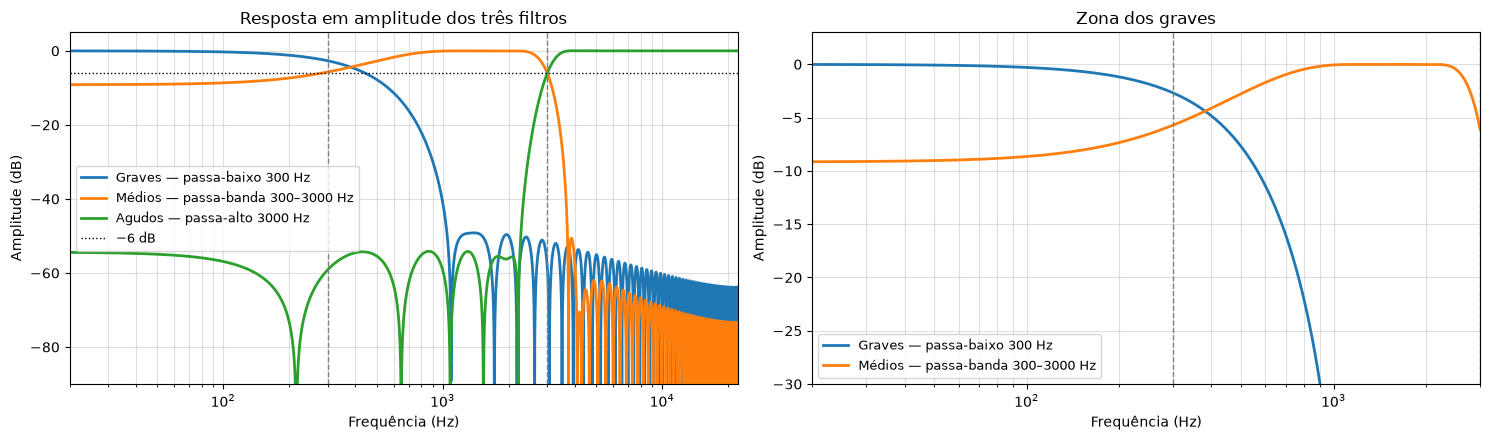

In [7]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 4.5))
for h, name in FILTERS:
    f, H = freq_response(h)
    ax1.plot(f, db(H), lw=2, label=name)
ax1.axhline(-6, color='k', ls=':', lw=1, label='−6 dB')
format_freq_axis(ax1, 'Resposta em amplitude dos três filtros', marks=(FC1, FC2))

f, Hl = freq_response(h_low)
_, Hm = freq_response(h_mid)
ax2.plot(f, db(Hl), lw=2, label=FILTERS[0][1])
ax2.plot(f, db(Hm), lw=2, label=FILTERS[1][1])
format_freq_axis(ax2, 'Zona dos graves', xlim=(20, 3000), ylim=(-30, 3), marks=(FC1, FC2))
plt.tight_layout(); plt.show()

**Interpretação:** Na banda de passagem, cada filtro tem ganho próximo de 0 dB. Fora da banda de transição, a atenuação é de pelo menos 50 dB. O passa-banda e o passa-alto cruzam-se a −6 dB em 3000 Hz.

Nos graves, o passa-baixo e o passa-banda sobrepõem-se (*gráfico da direita*). Com 101 coeficientes, a banda de transição tem cerca de 1,4 kHz. Esta largura é superior a toda a banda dos graves (0 a 300 Hz). Em 0 Hz, o passa-banda atenua apenas 9 dB. Em 600 Hz, o passa-baixo atenua apenas 11 dB.

### $1.3.$ Equalizador

Os três filtros estão associados em paralelo. A resposta impulsional do conjunto é a soma das respostas impulsionais, pesadas pelos ganhos:

$$h_{eq}[n] = g_1\, h_{graves}[n] + g_2\, h_{médios}[n] + g_3\, h_{agudos}[n]$$

O equalizador é um único filtro FIR com 101 coeficientes. Pela linearidade da convolução, filtrar com $h_{eq}$ produz a soma pesada das saídas das três bandas.

Com ganhos superiores a 1, a saída pode exceder o intervalo $[-1, 1]$. A normalização que evita o *clipping* é feita à saída do processador completo (secção $3$).

In [8]:
def equalizer_ir(g1, g2, g3):
    """Resposta impulsional do equalizador.
    Args:
        g1, g2, g3: Ganhos lineares dos graves, médios e agudos.
    Returns:
        h_eq = g1·h_low + g2·h_mid + g3·h_high.
    """
    return g1 * h_low + g2 * h_mid + g3 * h_high

def equalizer(x, g1, g2, g3):
    """Aplica o equalizador de 3 bandas.
    Args:
        x: Sinal de entrada.
        g1, g2, g3: Ganhos lineares dos graves, médios e agudos.
    Returns:
        x_eq, com o comprimento de x.
    """
    return lfilter(equalizer_ir(g1, g2, g3), 1.0, x)

CONFIGS = [(BASS_BOOST,   'Bass Boost'),
           (TREBLE_BOOST, 'Treble Boost')]

### $1.4.$ Resposta em Frequência Combinada

| Configuração | $(g_1, g_2, g_3)$ | Ganho ideal (graves / médios / agudos) |
| :--- | :--- | :--- |
| *Bass Boost* | $(2; 1; 0,5)$ | $+6$ / $0$ / $−6$ dB |
| *Treble Boost* | $(0,5; 1; 2)$ | $−6$ / $0$ / $+6$ dB |

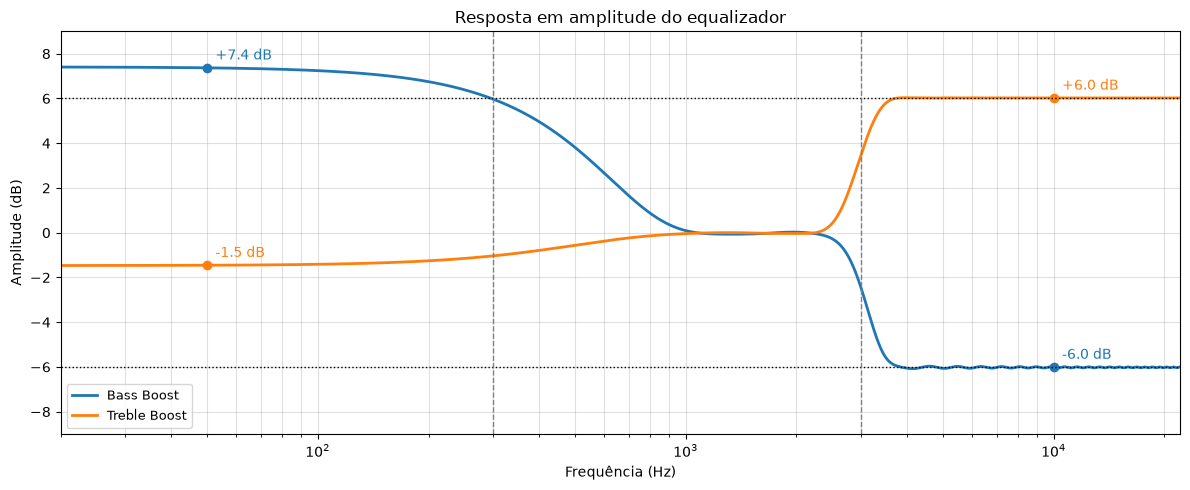

In [9]:
fig, ax = plt.subplots(figsize=(12, 5))
for k, (gains, name) in enumerate(CONFIGS):
    f, H = freq_response(equalizer_ir(*gains))
    ax.plot(f, db(H), lw=2, color=f'C{k}', label=name)
    for f0 in (50, 10000):
        v = db(H[np.argmin(np.abs(f - f0))])
        ax.plot(f0, v, 'o', color=f'C{k}')
        ax.annotate(f'{v:+.1f} dB', (f0, v), textcoords='offset points', xytext=(6, 6), color=f'C{k}')
for level in (6.02, -6.02):
    ax.axhline(level, color='k', ls=':', lw=1)
format_freq_axis(ax, 'Resposta em amplitude do equalizador', ylim=(-9, 9), marks=(FC1, FC2))
plt.tight_layout(); plt.show()

**Interpretação:** Nos médios, o ganho é 0 dB nas duas configurações. Nos agudos, o ganho é ±6 dB.

Nos graves, o passa-banda deixa passar cerca de 35% da amplitude. Por isso, o ganho real dos graves é $g_1 + 0{,}35\, g_2$. O *Bass Boost* dá +7,4 dB em vez de +6 dB. O *Treble Boost* dá −1,4 dB em vez de −6 dB.

### $1.5.$ Validação com Sinusóides

Num SLIT, uma sinusóide de frequência $\omega$ sai com a mesma frequência e com a amplitude multiplicada por $|H(\omega)|$. Aplicam-se ao equalizador sinusóides de amplitude 1. A amplitude de saída é comparada com $|H|$ calculado pelo `freqz`.

In [10]:
SIN_FREQS = [100, 300, 1000, 3000, 8000]
t_sin = np.arange(Fs) / Fs # 1 s

def sin_gain(f0, gains):
    """Amplitude de saída do equalizador para uma sinusóide de amplitude 1.
    Args:
        f0: Frequência da sinusóide (Hz).
        gains: Ganhos (g1, g2, g3).
    Returns:
        Pico da saída, sem as primeiras M amostras.
    """
    y = equalizer(np.sin(2 * np.pi * f0 * t_sin), *gains)
    return np.max(np.abs(y[L - 1:]))

measured = {name: [sin_gain(f0, gains) for f0 in SIN_FREQS] for gains, name in CONFIGS}

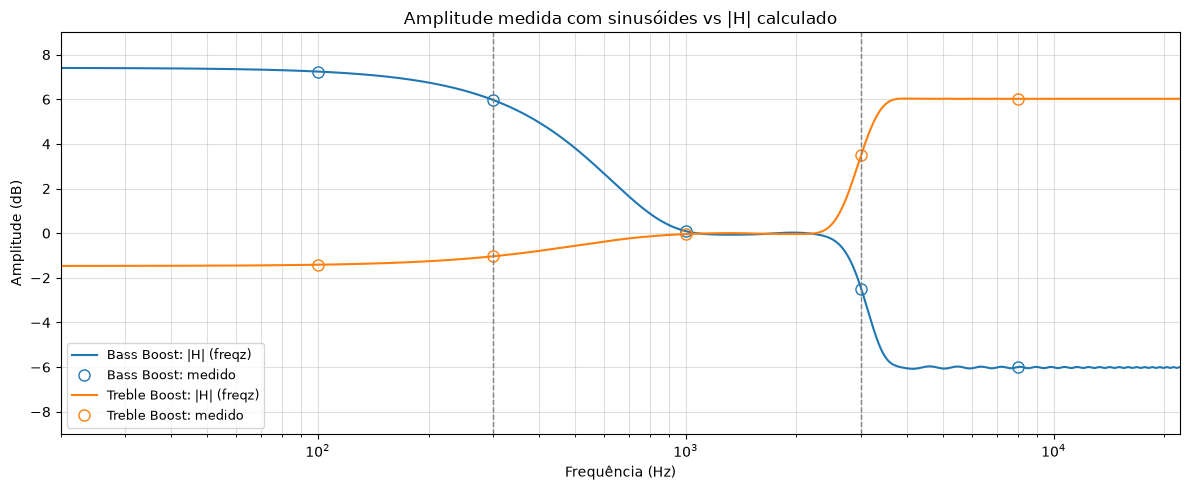

In [11]:
fig, ax = plt.subplots(figsize=(12, 5))
for k, (gains, name) in enumerate(CONFIGS):
    f, H = freq_response(equalizer_ir(*gains))
    ax.plot(f, db(H), lw=1.5, color=f'C{k}', label=f'{name}: |H| (freqz)')
    ax.plot(SIN_FREQS, db(np.array(measured[name])), 'o', ms=8, mfc='none', color=f'C{k}',
            label=f'{name}: medido')
format_freq_axis(ax, 'Amplitude medida com sinusóides vs |H| calculado', ylim=(-9, 9), marks=(FC1, FC2))
plt.tight_layout(); plt.show()

**Interpretação:** As amplitudes medidas no domínio do tempo coincidem com as curvas de $|H|$ calculadas pelo `freqz`.

## $2.$ **Parte B:** Reverberador de Schroeder

O reverberador associa 2 blocos em série: um banco de 4 filtros *Comb* em paralelo, seguido de uma cascata de 2 filtros *All-Pass*. Os dois tipos de filtro são sistemas recursivos (IIR), porque a saída depende de valores passados da própria saída.

In [12]:
T_COMB = (29.7, 37.1, 41.1, 43.7) # atrasos dos filtros Comb (ms)
G_COMB = (0.75, 0.75, 0.75, 0.75) # ganhos de realimentação, em [0.70, 0.80]
T_AP   = (5.0, 1.7)               # atrasos dos filtros All-Pass (ms)
A_AP   = 0.7                      # coeficiente dos filtros All-Pass

### $2.1.$ Atrasos

Um atraso de $T$ ms corresponde a $N = \mathrm{round}(T \cdot F_s / 1000)$ amostras.

In [13]:
N_COMB = [round(t * Fs / 1000) for t in T_COMB]
N_AP   = [round(t * Fs / 1000) for t in T_AP]

In [14]:
print('N_COMB =', N_COMB)
print('N_AP   =', N_AP)

N_COMB = [1310, 1636, 1813, 1927]
N_AP   = [220, 75]


### $2.2.$ Filtro *Comb*

A equação às diferenças, dada no enunciado, é

$$y_c[n] = x[n] + g\, y_c[n - N].$$

Aplicando a TZ, a função de transferência é

$$H_c(z) = \frac{1}{1 - g\, z^{-N}}.$$

Os $N$ pólos têm raio $g^{1/N} < 1$. Por isso, o sistema causal é estável. A resposta impulsional é uma sequência de impulsos espaçados de $N$ amostras, multiplicados por $g$ a cada $N$ amostras:

$$h_c[n] = \sum_{m=0}^{\infty} g^m\, \delta[n - mN].$$

A resposta em amplitude tem máximos $1/(1-g)$ em $f = k\, F_s/N$ e mínimos $1/(1+g)$. Estes picos reforçam frequências igualmente espaçadas, o que se ouve como uma ressonância metálica.

A razão entre máximos e mínimos, $(1+g)/(1-g)$, cresce com $g$. No intervalo do enunciado, vai de 15,1 dB ($g = 0{,}70$) a 19,1 dB ($g = 0{,}80$). Os quatro filtros usam $g = 0{,}75$. O RT60 resultante (secção $2.5$) fica no intervalo ótimo para voz, de 0,5 a 1,5 s.

No banco, $H_{comb}(z) = \sum_{k=1}^{4} H_{c,k}(z)$. Os picos de dois *Comb* coincidem nos múltiplos de $F_s/\mathrm{mdc}(N_i, N_j)$. Só o par 1310 e 1636 tem $\mathrm{mdc} = 2$. Os picos deste par coincidem também em 22 050 Hz, fora da banda audível.

In [15]:
def comb_coefs(N, g):
    """Coeficientes de H(z) = 1 / (1 - g·z^-N).
    Args:
        N: Atraso (amostras).
        g: Ganho de realimentação.
    Returns:
        (b, a): numerador e denominador.
    """
    a = np.zeros(N + 1)
    a[0], a[N] = 1.0, -g
    return np.array([1.0]), a


h_comb1 = lfilter(*comb_coefs(N_COMB[0], G_COMB[0]), unit_impulse(Fs // 2))

f_comb = np.linspace(0, 250, 5000)
H_combs = [freq_response(*comb_coefs(N, g), worN=f_comb)[1] for N, g in zip(N_COMB, G_COMB)]
H_bank = np.sum(H_combs, axis=0)

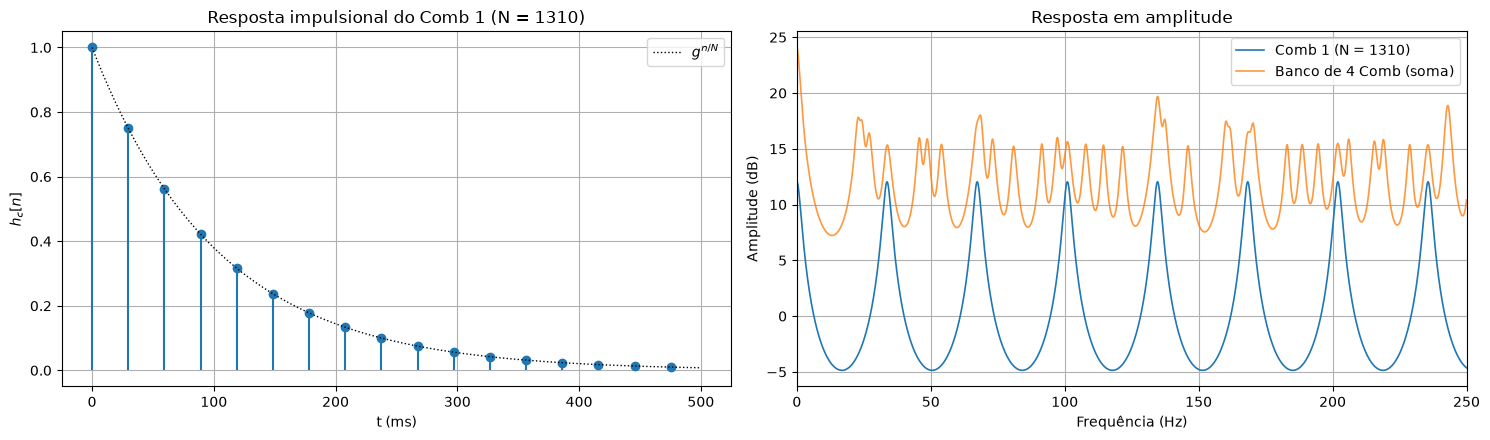

In [16]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 4.5))
n = np.arange(len(h_comb1))
nz = np.flatnonzero(h_comb1)
ax1.stem(1000 * nz / Fs, h_comb1[nz], basefmt=' ')
ax1.plot(1000 * n / Fs, G_COMB[0] ** (n / N_COMB[0]), 'k:', lw=1, label=r'$g^{n/N}$')
ax1.set_xlabel('t (ms)'); ax1.set_ylabel(r'$h_c[n]$'); ax1.legend()
ax1.set_title(f'Resposta impulsional do Comb 1 (N = {N_COMB[0]})')

ax2.plot(f_comb, db(H_combs[0]), lw=1.2, label=f'Comb 1 (N = {N_COMB[0]})')
ax2.plot(f_comb, db(H_bank), lw=1.2, alpha=0.8, label='Banco de 4 Comb (soma)')
ax2.set_xlabel('Frequência (Hz)'); ax2.set_ylabel('Amplitude (dB)'); ax2.set_xlim(0, 250)
ax2.set_title('Resposta em amplitude'); ax2.legend()
plt.tight_layout(); plt.show()

**Interpretação:** No gráfico da esquerda, os impulsos de $h_c[n]$ estão espaçados de 1310 amostras (29,7 ms).

No gráfico da direita, os picos do *Comb* 1 valem +12 dB e estão espaçados de $F_s/N \approx 33{,}7$ Hz. Os mínimos valem −4,9 dB. No banco, os picos dos quatro filtros ficam em posições diferentes. A resposta deixa de ser periódica. Em $f = 0$, os quatro picos somam-se e o ganho chega a 16 (+24 dB).

### $2.3.$ Filtro *All-Pass*

A equação às diferenças é

$$y_{ap}[n] = -a\, x[n] + x[n - N] + a\, y_{ap}[n - N].$$

Aplicando a TZ, a função de transferência é

$$H_{ap}(z) = \frac{-a + z^{-N}}{1 - a\, z^{-N}}.$$

Os pólos têm raio $|z| = a^{1/N} < 1$, pelo que o sistema causal é estável. Os zeros são as raízes de $z^N = 1/a$ e têm raio $|z| = a^{-1/N} > 1$. Cada zero está na direção de um pólo, com o raio inverso.

$|H(\omega)|$ é proporcional ao produto das distâncias de $e^{j\omega}$ aos zeros, dividido pelo produto das distâncias aos pólos. Para cada par pólo-zero, o quociente destas distâncias é constante, e o resultado é $|H_{ap}(\omega)| = 1$ em todas as frequências. O filtro altera apenas a fase do sinal.

In [ ]:
def allpass_coefs(N, a):
    """Coeficientes de H(z) = (-a + z^-N) / (1 - a·z^-N).
    Args:
        N: Atraso (amostras).
        a: Coeficiente do filtro.
    Returns:
        (b, a): numerador e denominador.
    """
    num, den = np.zeros(N + 1), np.zeros(N + 1)
    num[0], num[N] = -a, 1.0
    den[0], den[N] = 1.0, -a
    return num, den

h_ap1 = lfilter(*allpass_coefs(N_AP[0], A_AP), unit_impulse(int(0.030 * Fs)))
H_aps = [freq_response(*allpass_coefs(N, A_AP)) for N in N_AP]

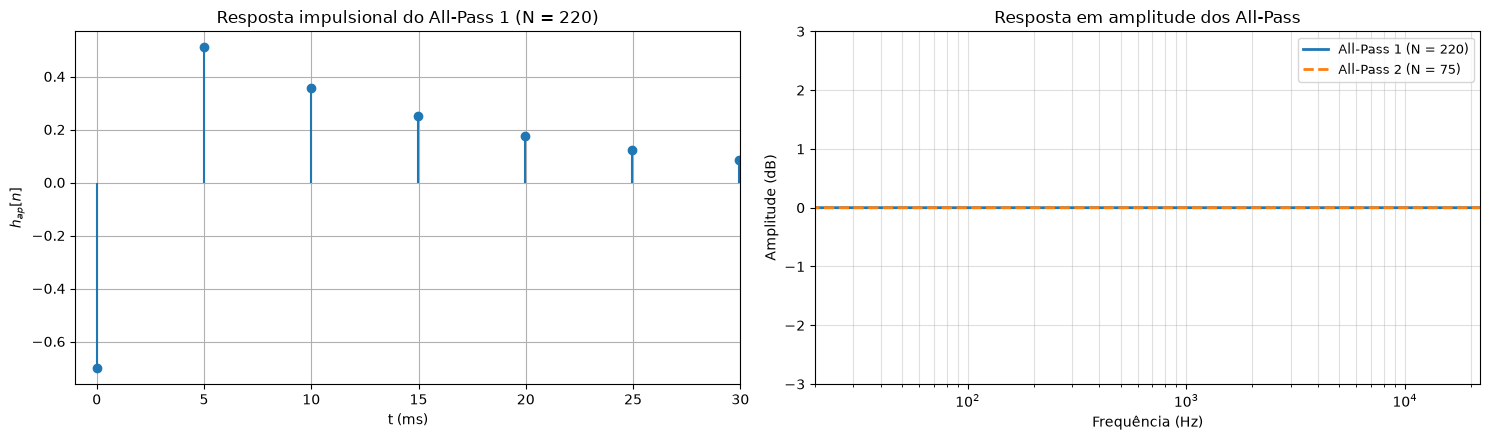

In [18]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 4.5))
nz = np.flatnonzero(h_ap1)
ax1.stem(1000 * nz / Fs, h_ap1[nz], basefmt=' ')
ax1.set_xlim(-1, 1000 * len(h_ap1) / Fs)
ax1.set_xlabel('t (ms)'); ax1.set_ylabel(r'$h_{ap}[n]$')
ax1.set_title(f'Resposta impulsional do All-Pass 1 (N = {N_AP[0]})')

for k, (f, H) in enumerate(H_aps):
    ax2.plot(f, db(H), lw=2, ls=['-', '--'][k], label=f'All-Pass {k + 1} (N = {N_AP[k]})')
format_freq_axis(ax2, 'Resposta em amplitude dos All-Pass', ylim=(-3, 3), marks=())
plt.tight_layout(); plt.show()

**Interpretação:** O primeiro impulso de $h_{ap}[n]$ vale $-a = -0{,}7$. Os seguintes estão espaçados de 220 amostras (4,99 ms). Confirma-se $|H_{ap}(\omega)| = 1$. O *All-Pass* aumenta, portanto, o número de impulsos sem reforçar nenhuma frequência.

### $2.4.$ Reverberador Completo

A função de transferência do reverberador é

$$H_{reverb}(z) = \left(\sum_{k=1}^{4} H_{c,k}(z)\right) H_{ap,1}(z)\, H_{ap,2}(z).$$

Todos os pólos estão no interior do círculo de raio unitário. Por isso, o reverberador é estável.

Num *Comb*, a amplitude dos impulsos cai $20\log_{10} g$ dB a cada $N/F_s$ segundos. A taxa de decaimento, em dB/s, é

$$D = \frac{20\log_{10}(g)\, F_s}{N}.$$

O tempo de reverberação, RT60, é o tempo que a cauda leva a decair 60 dB: $\mathrm{RT60} = -60/D$. O *Comb* com maior atraso tem a taxa mais lenta e determina o RT60.

In [ ]:
def reverb(x):
    """Aplica o reverberador de Schroeder (4 Comb em paralelo + 2 All-Pass em série).
    Args:
        x: Sinal de entrada.
    Returns:
        y_reverb, com o comprimento de x.
    """
    y = sum(lfilter(*comb_coefs(N, g), x) for N, g in zip(N_COMB, G_COMB))
    for N in N_AP:
        y = lfilter(*allpass_coefs(N, A_AP), y)
    return y

def decay_rate(N, g):
    """Taxa de decaimento de um filtro Comb.
    Args:
        N: Atraso (amostras).
        g: Ganho de realimentação.
    Returns:
        Taxa (dB/s).
    """
    return 20 * np.log10(g) * Fs / N

RATE_COMB = [decay_rate(N, g) for N, g in zip(N_COMB, G_COMB)]

### $2.5.$ Resposta Impulsional

A resposta impulsional $h[n]$ do reverberador obtém-se com $x[n] = \delta[n]$.

In [20]:
h_rev = reverb(unit_impulse(3 * Fs))

Taxa de decaimento dos filtros Comb: -84.1 dB/s, -67.4 dB/s, -60.8 dB/s, -57.2 dB/s


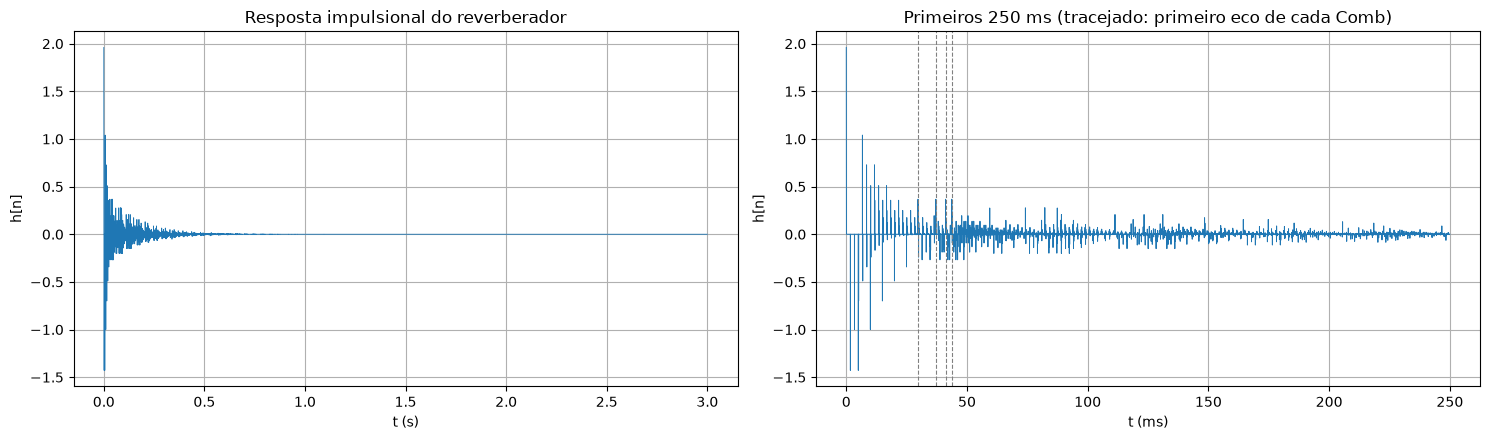

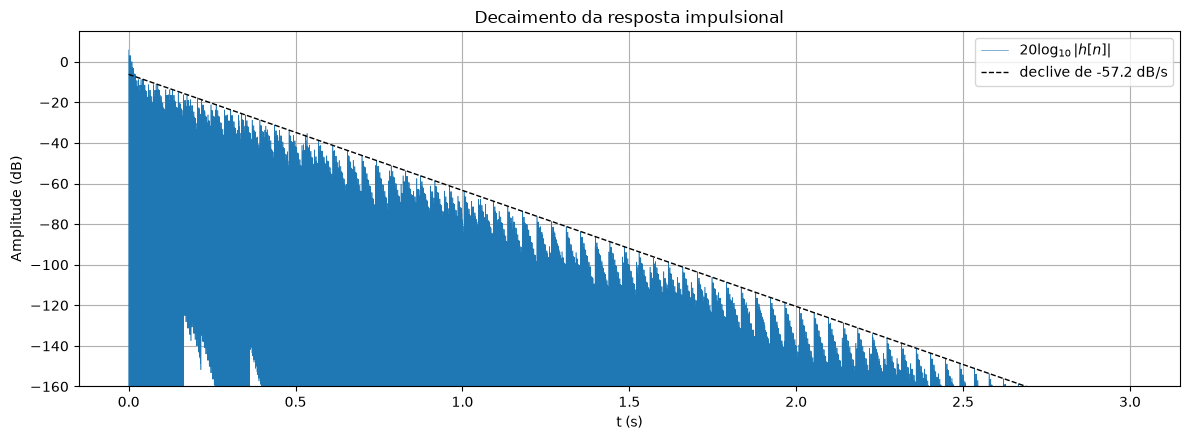

In [21]:
print('Taxa de decaimento dos filtros Comb:', ', '.join(f'{d:.1f} dB/s' for d in RATE_COMB))

t_h = np.arange(len(h_rev)) / Fs
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 4.5))
ax1.plot(t_h, h_rev, lw=0.6)
ax1.set_xlabel('t (s)'); ax1.set_ylabel('h[n]'); ax1.set_title('Resposta impulsional do reverberador')
lim = int(0.250 * Fs)
ax2.plot(1000 * t_h[:lim], h_rev[:lim], lw=0.7)
for N in N_COMB:
    ax2.axvline(1000 * N / Fs, color='gray', ls='--', lw=0.8)
ax2.set_xlabel('t (ms)'); ax2.set_ylabel('h[n]')
ax2.set_title('Primeiros 250 ms (tracejado: primeiro eco de cada Comb)')
plt.tight_layout(); plt.show()

n0 = max(N_COMB)                                              # primeiro eco do Comb mais lento
env0 = db(np.max(np.abs(h_rev[n0:])))
fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(t_h, db(h_rev), lw=0.4, label=r'$20\log_{10}|h[n]|$')
ax.plot(t_h, env0 + max(RATE_COMB) * (t_h - n0 / Fs), 'k--', lw=1,
        label=f'declive de {max(RATE_COMB):.1f} dB/s')
ax.set_xlabel('t (s)'); ax.set_ylabel('Amplitude (dB)'); ax.set_ylim(-160, 15)
ax.set_title('Decaimento da resposta impulsional'); ax.legend()
plt.tight_layout(); plt.show()

**Interpretação:** Nos primeiros milissegundos, $h[n]$ tem apenas impulsos isolados. Estes impulsos resultam de $\delta[n]$ espalhado pelos *All-Pass*, com espaçamentos de 220 e 75 amostras. Os primeiros ecos dos *Comb* surgem entre 29,7 e 43,7 ms (linhas a tracejado). Cada eco é também espalhado pelos *All-Pass*. Por isso, a densidade de impulsos aumenta com o tempo. No fim dos 250 ms, os impulsos já não se distinguem, e forma-se o campo reverberante.

Em dB, a envolvente de $h[n]$ decai em linha reta. Isto corresponde a um decaimento exponencial da amplitude. O declive acompanha a taxa do *Comb* mais lento, cerca de −57 dB/s. O RT60 é, portanto, cerca de 1,05 s.

## $3.$ Processador completo

O processador aplica o equalizador, o reverberador e a mistura definida na introdução. Antes de processar, acrescentam-se ao fim da entrada zeros com a duração do RT60 (cerca de 1,05 s, secção $2.5$). Desta forma, a cauda de reverberação fica completa na saída. No fim, a saída é normalizada pelo pico ($\max|y| = 0{,}99$). Esta normalização evita o *clipping* e só altera o volume.

In [22]:
def processor(x, gains, alpha):
    """Aplica o processador completo: equalizador, reverberador e mistura.
    Args:
        x: Sinal de entrada.
        gains: Ganhos do equalizador (g1, g2, g3).
        alpha: Proporção de som reverberado, em [0, 1].
    Returns:
        y normalizado, com a cauda de reverberação acrescentada.
    """
    x = np.concatenate([x, np.zeros(round(-60 / max(RATE_COMB) * Fs))])
    x_eq = equalizer(x, *gains)
    return normalize((1 - alpha) * x_eq + alpha * reverb(x_eq))

## $4.$ Teste com Áudio

O teste usa dois sinais secos, uma voz e um instrumento. Cada sinal é processado com uma das configurações da secção $1.4$. A voz usa o *Treble Boost*, que reforça os agudos. O instrumento usa o *Bass Boost*, que reforça os graves. Os sinais originais estão em `audio/in/`, e os resultados são gravados em `audio/out/` com o mesmo nome.

Cada filtro *Comb* deixa passar $x[n]$ sem atraso. Por isso, $y_{reverb}[n]$ também contém som direto. O valor $\alpha = 0{,}25$ foi escolhido por audição. Um $\alpha$ maior faz o som reverberado dominar o som direto, e a voz perde inteligibilidade.

In [ ]:
TESTS = {'voz_seca':         CONFIGS[1],
         'instrumento_seco': CONFIGS[0]}

ALPHA = 0.25 # proporção de som reverberado

signals = {}
for name, (gains, _) in TESTS.items():
    x = read_wav(f'{AUDIO_IN}/{name}.wav')
    y = processor(x, gains, ALPHA)
    write_wav(f'{AUDIO_OUT}/{name}.wav', y)
    signals[name] = (x, y)

C:\Users\bruno\AppData\Local\Temp\ipykernel_21876\3120473385.py:37: WavFileWarning: Chunk (non-data) not understood, skipping it.
  _, x = wavfile.read(path)


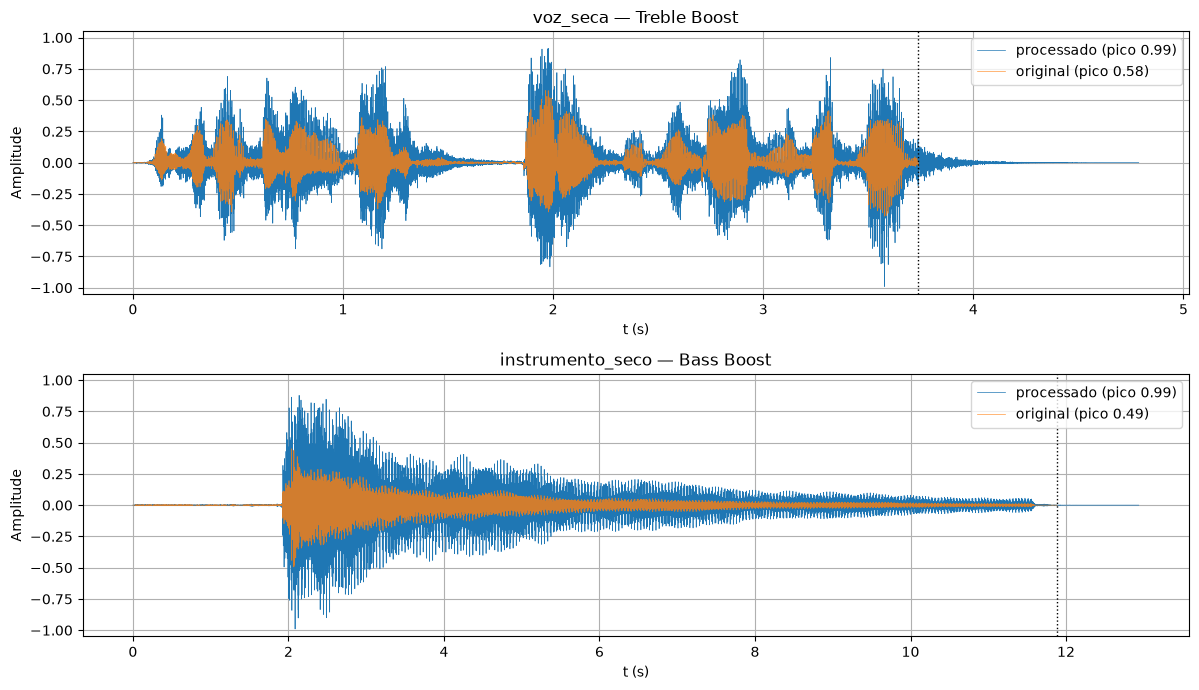

In [24]:
fig, axs = plt.subplots(len(signals), 1, figsize=(12, 3.5 * len(signals)))
for ax, (name, (x, y)) in zip(axs, signals.items()):
    ax.plot(np.arange(len(y)) / Fs, y, lw=0.5, label=f'processado (pico {np.max(np.abs(y)):.2f})')
    ax.plot(np.arange(len(x)) / Fs, x, lw=0.5, alpha=0.8, label=f'original (pico {np.max(np.abs(x)):.2f})')
    ax.axvline(len(x) / Fs, color='k', ls=':', lw=1)
    ax.set_xlabel('t (s)'); ax.set_ylabel('Amplitude'); ax.set_ylim(-1.05, 1.05)
    ax.set_title(f'{name} — {TESTS[name][1]}'); ax.legend(loc='upper right')
plt.tight_layout(); plt.show()

In [25]:
for name, (x, y) in signals.items():
    print(f'{name} — original'); display(Audio(x, rate=Fs))
    print(f'{name} — processado'); display(Audio(y, rate=Fs))

voz_seca — original


voz_seca — processado


instrumento_seco — original


instrumento_seco — processado


**Interpretação:** Depois do fim do sinal original (linha a ponteado), a saída continua com a cauda de reverberação. Na voz, o *Treble Boost* reforça os agudos em 6 dB, mas só atenua os graves 1,4 dB (secção $1.4$). A cauda não tem uma frequência dominante, porque os picos dos quatro *Comb* não coincidem (secção $2.2$).